In [39]:
#!pip install scikit-fuzzy

In [40]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import numpy as np


###  **Variables de entrada (Antecedentes)**
#### Severidad del ataque (SA)
#### Vulnerabilidad del sistema (VS)
#### Exposicion al ataque (EA)
#### Capacidad de respuesta (CR)

In [41]:

SA = ctrl.Antecedent(np.arange(0,11,1), 'severidad ataque')
VS = ctrl.Antecedent(np.arange(0,11,1), 'vulnerabilidad sistema')
EA = ctrl.Antecedent(np.arange(0,11,1), 'Exposición ataque')
CR = ctrl.Antecedent(np.arange(0,11,1), 'Capacidad respuesta')

### **Variables de salida (Consecuentes)**

#### Nivel de riesgo (NR)

In [72]:
NR = ctrl.Consequent(np.arange(0,11,1),'Nivel')

### **Conjuntos difusos**

In [43]:
SA['Sin impacto'] = fuzz.trapmf(SA.universe, [0,0,1,2])
SA['Minimo'] = fuzz.trimf(SA.universe, [1,2,3])
SA['Bajo'] = fuzz.trapmf(SA.universe, [2,3,4,5])
SA['Moderado'] = fuzz.trimf(SA.universe, [4,5,6])
SA['Alto'] = fuzz.trapmf(SA.universe, [5,6,7,8])
SA['Critico'] = fuzz.trapmf(SA.universe, [7,8,10,10])

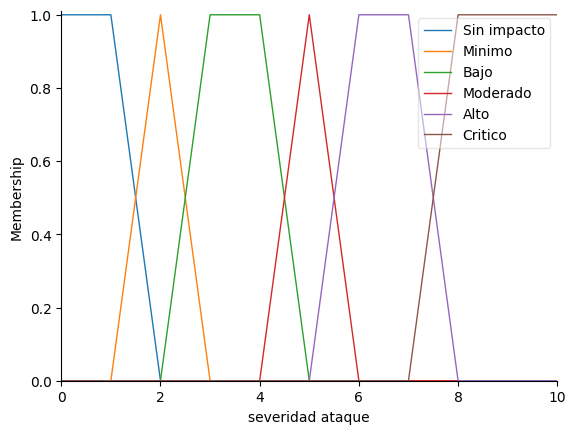

In [44]:
SA.view()

In [45]:
VS['baja'] = fuzz.trapmf(VS.universe, [0,0,1,2])
VS['media baja'] = fuzz.trapmf(VS.universe, [1,2,3,4])
VS['media'] = fuzz.trapmf(VS.universe, [3,4,5,7])
VS['alta'] = fuzz.trapmf(VS.universe, [5,7,10,10])

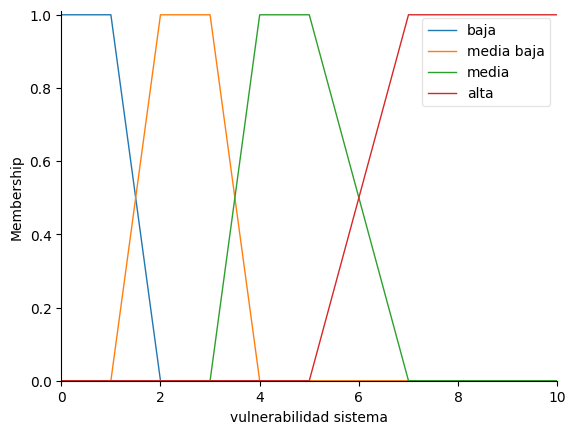

In [46]:
VS.view()

In [47]:
EA['Minima'] = fuzz.trapmf(EA.universe, [0,0,2,3])
EA['Baja'] = fuzz.trapmf(EA.universe, [2,3,5,6])
EA['Moderada'] = fuzz.trapmf(EA.universe, [5,6,7,8])
EA['Alta'] = fuzz.trapmf(EA.universe,[7,8,10,10])

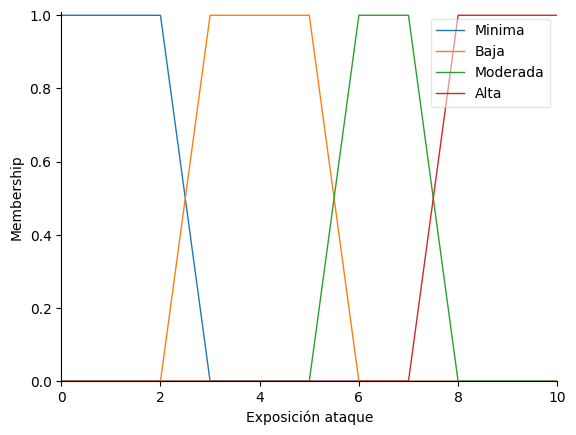

In [48]:
EA.view()

In [49]:
CR['Muy limitada'] = fuzz.trimf(CR.universe,[0,0,1])
CR['Basica'] = fuzz.trapmf(CR.universe, [0,1,3,4])
CR['Adecuada'] = fuzz.trapmf(CR.universe, [3,4,7,8])
CR['Avanzada'] = fuzz.trapmf(CR.universe, [6,8,10,10])

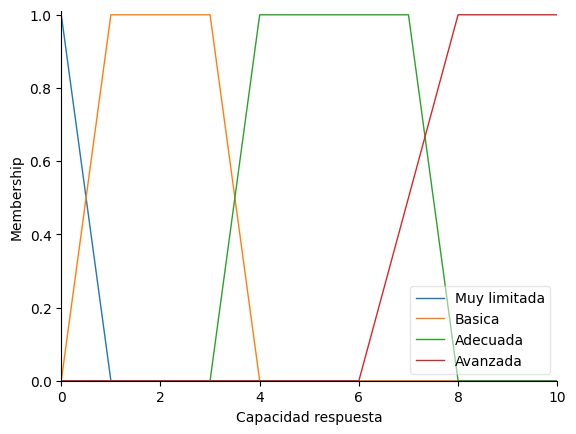

In [50]:
CR.view()

In [73]:
NR['Muy bajo'] = fuzz.trimf(NR.universe, [0,0,1])
NR['Bajo'] = fuzz.trapmf(NR.universe, [0,1,3,4])
NR['Moderado'] = fuzz.trapmf(NR.universe, [3,4,5,6])
NR['Alto'] = fuzz.trimf(NR.universe, [5,6,8])
NR['Critico'] = fuzz.trapmf(NR.universe, [6,8,10,10])

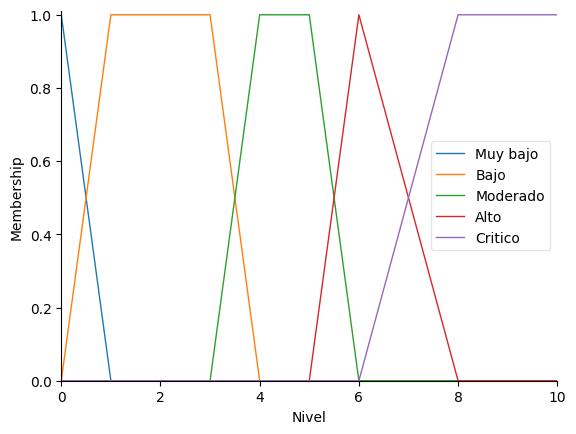

In [74]:
NR.view()

## Crear reglas

In [75]:

# Reglas para Nivel de Riesgo Muy Bajo
rule1 = ctrl.Rule(antecedent=(SA['Sin impacto'] & VS['baja'] & EA['Minima'] & CR['Avanzada']), consequent=NR['Muy bajo'])
rule2 = ctrl.Rule(antecedent=(SA['Minimo'] & VS['baja'] & CR['Avanzada']), consequent=NR['Muy bajo'])

# Reglas para Nivel de Riesgo Bajo
rule3 = ctrl.Rule(antecedent=(SA['Minimo'] & VS['media baja'] & EA['Baja']), consequent=NR['Bajo'])
rule4 = ctrl.Rule(antecedent=(SA['Bajo'] & CR['Adecuada']), consequent=NR['Bajo'])

# Reglas para Nivel de Riesgo Moderado
rule5 = ctrl.Rule(antecedent=(SA['Moderado'] & VS['media'] & EA['Moderada']), consequent=NR['Moderado'])
rule6 = ctrl.Rule(antecedent=(SA['Bajo'] & EA['Moderada'] & CR['Basica']), consequent=NR['Moderado'])

# Reglas para Nivel de Riesgo Alto
rule7 = ctrl.Rule(antecedent=(SA['Alto'] & VS['alta'] & EA['Alta']), consequent=NR['Alto'])
rule8 = ctrl.Rule(antecedent=(SA['Moderado'] & VS['alta'] & CR['Basica']), consequent=NR['Alto'])

# Reglas para Nivel de Riesgo Crítico
rule9 = ctrl.Rule(antecedent=(SA['Critico'] & VS['alta'] & EA['Alta'] & CR['Muy limitada']), consequent=NR['Critico'])
rule10 = ctrl.Rule(antecedent=(SA['Alto'] & EA['Alta'] & CR['Muy limitada']), consequent=NR['Critico'])




In [76]:
# Sistema de control y la simulación
riesgo_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9, rule10])
riesgo_sim = ctrl.ControlSystemSimulation(riesgo_ctrl)

In [82]:
# Asignando algunas entradas para probar el sistema
riesgo_sim.input['severidad ataque'] = 1
riesgo_sim.input['vulnerabilidad sistema'] = 1
riesgo_sim.input['Exposición ataque'] = 2
riesgo_sim.input['Capacidad respuesta'] = 7


In [83]:
# Computando el resultado
riesgo_sim.compute()

e:\Onedrive Personal\OneDrive\U\2024\FD\taller2\codigo_FIS\fis_env\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


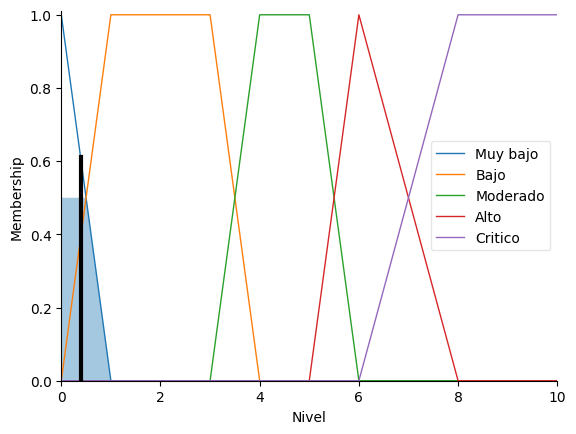

In [86]:
# Imprimiendo el nivel de riesgo resultante
output_riesgo = riesgo_sim.output['Nivel']
output_riesgo
NR.view(sim=riesgo_sim)